# Clase de repaso: NumPy + pandas + Matplotlib

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Configuración consistente para todas las figuras del notebook.
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.constrained_layout.use": True,
})
#Configuracion de pandas
pd.set_option("display.precision", 5)

NumPy: 2.1.3 | pandas: 2.2.3


## 0. Cuidado

Al nombrar archivos, eviten utilizar espacios, ya que pueden generar problemas de compatibilidad al trabajar con distintos sistemas operativos o ejecutar comandos desde la terminal. Se recomienda utilizar guiones bajos (_) para separar las palabras.

Por ejemplo:
- Incorrecto: Tarea 5.ipynb
- Correcto: Tarea_5.ipynb

### Decoradores

Un **decorador** es una herramienta de Python que permite modificar o extender el comportamiento de una función o método sin cambiar directamente su código.

Los decoradores se escriben utilizando el símbolo @ antes de definir una función.

In [92]:
def decorador(funcion):
    def nueva_funcion():
        print("Antes de ejecutar")
        funcion()
        print("Después de ejecutar")
    return nueva_funcion


@decorador
def saludar():
    print("¡Hola, mundo!")


saludar()

Antes de ejecutar
¡Hola, mundo!
Después de ejecutar


## 1. Clases en Python
Una clase permite reunir información (atributos) y funcionalidades (métodos) dentro de un mismo objeto.

Por ejemplo, podemos representar una estrella utilizando tres atributos:
- nombre: identificador de la estrella.
- luminosidad: luminosidad expresada en unidades solares $L_\odot$.
- distancia: distancia expresada en parsecs (pc).
A partir de estos atributos, podemos definir métodos para calcular propiedades físicas, generar resúmenes y construir nuevas instancias.
### 1.1. Componentes de una clase
| Componente | Descripción |
|---|---|
| `class` | Define una clase. |
| `__init__` | Inicializa los atributos del objeto. |
| `self` | Hace referencia a la instancia actual. |
| Atributos | Almacenan información del objeto. |
| Métodos | Funciones definidas dentro de la clase. |
| `@property` | Permite acceder a un cálculo como si fuera un atributo. |
| `@classmethod` | Define un método asociado a la clase que recibe `cls` y permite crear instancias alternativas. |

### 1.2. Documentación de clases
En Python, es recomendable utilizar el formato de documentación NumPy, especialmente para código científico.
| Sección | ¿Qué documenta? |
|---|---|
| `Parameters` | Argumentos necesarios para construir el objeto. |
| `Attributes` | Información almacenada en la instancia. |
| `Methods` | Métodos disponibles. |
| `Returns` | Valores devueltos por un método. |
| `Raises` | Errores que puede producir una operación. |
| `Notes` | Información adicional y ecuaciones utilizadas. |
| `Examples` | Ejemplos de utilización. |

### 1.3. Ejemplo: clase Estrella
Definiremos una clase Estrella que almacena su nombre, luminosidad y distancia.

El flujo relativo se calcula mediante:

$F_{\mathrm{rel}} = \frac{L}{4\pi d^2}$

donde $L$ está expresada en luminosidades solares y $d$ en parsecs. La expresión proporciona un valor relativo y no un flujo calibrado físicamente.

In [ ]:
class Estrella:
    """
    Representa una estrella y calcula su flujo relativo.

    Parameters
    ----------
    nombre : str
        Nombre de la estrella.
    luminosidad : float
        Luminosidad en unidades solares (L_sun).
    distancia : float
        Distancia en parsecs (pc).

    Attributes
    ----------
    nombre : str
        Nombre de la estrella.
    luminosidad : float
        Luminosidad de la estrella.
    distancia : float
        Distancia a la estrella.

    Methods
    -------
    resumen()
        Devuelve un diccionario con las propiedades de la estrella.
    desde_diccionario(datos)
        Crea una estrella utilizando un diccionario.

    Notes
    -----
    El flujo relativo se calcula mediante:

        F = L / (4 * pi * d**2)

    Examples
    --------
    >>> estrella = Estrella("Sol", 1.0, 10.0)
    >>> estrella.flujo_relativo
    0.0007957747154594767
    """

    def __init__(self, nombre, luminosidad, distancia):
        self.nombre = nombre
        self.luminosidad = luminosidad
        self.distancia = distancia

    @property
    def flujo_relativo(self):
        """Calcula el flujo relativo de la estrella."""
        return self.luminosidad / (4 * np.pi * self.distancia**2)

    def resumen(self):
        """Devuelve un diccionario con las propiedades."""
        return {
            "nombre": self.nombre, "luminosidad": self.luminosidad, "distancia": self.distancia, "flujo_relativo": self.flujo_relativo}

    @classmethod
    def desde_diccionario(cls, datos):
        """
        Crea una estrella a partir de un diccionario.

        Parameters
        ----------
        datos : dict
            Diccionario con nombre, luminosidad y distancia.

        Returns
        -------
        Estrella
            Nueva instancia de la clase.
        """
        return cls(datos["nombre"], datos["luminosidad"], datos["distancia"])


In [ ]:
estrella1 = Estrella("Sirio", 25.4, 2.64)

print(estrella1.nombre)
print(estrella1.luminosidad)
print(estrella1.distancia)

Sirio
25.4
2.64


Utilizar @property:

In [ ]:
print(estrella1.flujo_relativo)

In [ ]:
datos = { "nombre": "Vega", "luminosidad": 40.1, "distancia": 7.68}

estrella2 = Estrella.desde_diccionario(datos)

print(estrella2.resumen())

{'nombre': 'Vega', 'luminosidad': 40.1, 'distancia': 7.68, 'flujo_relativo': 0.05410184409234792}


## 2. NumPy: dimensiones, vistas y *broadcasting*

Un arreglo de NumPy tiene una forma (`shape`). Operar con arreglos de formas distintas es posible cuando sus dimensiones son **compatibles por broadcasting**. Dos dimensiones son compatibles si son iguales o si una de ellas vale 1.

Ejemplo: un vector columna de forma `(5, 1)` multiplicado por un vector fila de forma `(1, 5)` produce una matriz `(5, 5)`.

vector: (5,)
columna: (5, 1)
fila: (1, 5)
producto: (5, 5)
[[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]


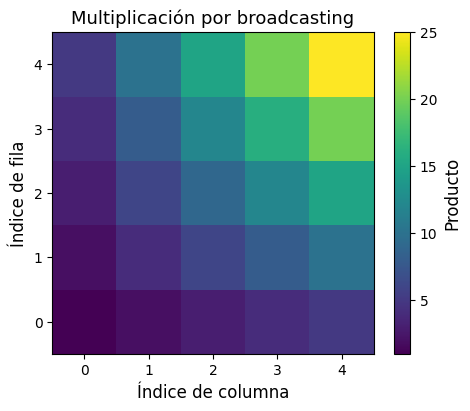

In [ ]:
valores = np.arange(1, 6)
columna = valores[:, np.newaxis]   # (5, 1)
fila = valores[np.newaxis, :]      # (1, 5)
tabla_producto = columna * fila   # (5, 5): broadcasting

print("vector:", valores.shape)
print("columna:", columna.shape)
print("fila:", fila.shape)
print("producto:", tabla_producto.shape)
print(tabla_producto)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(tabla_producto, origin="lower", cmap="viridis")
ax.set(xlabel="Índice de columna", ylabel="Índice de fila", title="Multiplicación por broadcasting")
fig.colorbar(im, ax=ax, label="Producto")
plt.show()

vector: (5,)
columna: (5, 1)
fila: (1, 5)
producto: (5, 5)
[[ 1  2  3  4  5]
 [ 2  4  6  8 10]
 [ 3  6  9 12 15]
 [ 4  8 12 16 20]
 [ 5 10 15 20 25]]


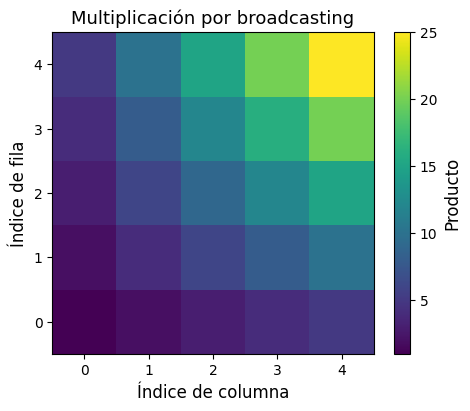

In [ ]:
valores = np.arange(1, 6)
columna = valores[:, None]   # (5, 1)
fila = valores[None, :]      # (1, 5)
tabla_producto = columna * fila   # (5, 5): broadcasting

print("vector:", valores.shape)
print("columna:", columna.shape)
print("fila:", fila.shape)
print("producto:", tabla_producto.shape)
print(tabla_producto)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(tabla_producto, origin="lower", cmap="viridis")
ax.set(xlabel="Índice de columna", ylabel="Índice de fila", title="Multiplicación por broadcasting")
fig.colorbar(im, ax=ax, label="Producto")
plt.show()

In [ ]:
x_mascara = np.array([20, 40, 60])
y_mascara = 35
r_mascara = np.array([5, 10, 15])

x_mascara, y_mascara, r_mascara = np.broadcast_arrays(x_mascara,y_mascara,r_mascara)

print(x_mascara)
print(y_mascara)
print(r_mascara)

[20 40 60]
[35 35 35]
[ 5 10 15]


### ¿Cuándo usar `.copy()`?

Un *slice* generalmente devuelve una **vista** del arreglo original: modificar esa vista puede cambiar los datos originales. `.copy()` crea un arreglo independiente. En pandas, para trabajar sin alterar un DataFrame de origen, también es útil `.copy()`.

In [ ]:
original = np.arange(8)
vista = original[::2]
copia = original[::2].copy()

vista[0] = 99
copia[1] = -5

print("Original:", original)  # Se modificó a través de 'vista'.
print("Vista:   ", vista)
print("Copia:   ", copia)     # No modifica 'original'.
print("¿Comparten memoria original y vista?", np.shares_memory(original, vista))
print("¿Comparten memoria original y copia?", np.shares_memory(original, copia))

Original: [99  1  2  3  4  5  6  7]
Vista:    [99  2  4  6]
Copia:    [ 0 -5  4  6]
¿Comparten memoria original y vista? True
¿Comparten memoria original y copia? False


## 3. Construcción de un catálogo estelar con NumPy y pandas

Simularemos **150 estrellas** con luminosidad, distancia y temperatura. Para practicar operaciones vectorizadas, definimos una magnitud proporcional al flujo observado:

$F_{\rm rel} = \frac{L/L_\odot}{4\pi\,(d/{\rm pc})^2}$.

Este `flujo_rel` es un **indicador en unidades arbitrarias**, no un flujo calibrado en unidades físicas. Consideraremos «detectado» al 35 % con mayor `flujo_rel`: es un criterio didáctico basado en percentiles, no un límite instrumental real.

In [ ]:
n_estrellas = 150

catalogo = pd.DataFrame({ "id": [f"EST-{i:03d}" for i in range(1, n_estrellas + 1)], "L_Lsol": rng.uniform(0.5, 120.0, size=n_estrellas), "d_pc": rng.uniform(20.0, 600.0, size=n_estrellas),
    "T_K": rng.uniform(3000.0, 10000.0, size=n_estrellas),})

catalogo["flujo_rel"] = catalogo["L_Lsol"] / (4 * np.pi * catalogo["d_pc"]**2)

# Grupos pedagógicos: no corresponden a una clasificación espectral formal.
catalogo["grupo_temp"] = pd.cut(catalogo["T_K"],bins=[0, 5000, 7500, np.inf],labels=["Fría", "Intermedia", "Caliente"],right=False,)

umbral = np.quantile(catalogo["flujo_rel"].to_numpy(), 0.65)
catalogo["detectada"] = catalogo["flujo_rel"] >= umbral

print(f"Umbral de detección didáctico: {umbral:.3e}")
catalogo.head()

Umbral de detección didáctico: 8.246e-05


,id,L_Lsol,d_pc,T_K,flujo_rel,grupo_temp,detectada
0,EST-001,26.14287,194.55024,8337.72503,5.49642e-05,Caliente,False
1,EST-002,49.31917,303.37875,4893.74459,4.26418e-05,Fría,False
2,EST-003,102.48167,404.46124,5549.34412,4.98520e-05,Intermedia,False
3,EST-004,28.45577,574.26149,5201.07986,6.86659e-06,Intermedia,False
4,EST-005,7.46718,186.13881,4103.28154,1.71503e-05,Fría,False


### `percentile` y `quantile`

Los percentiles, cuantiles y cuartiles son medidas estadísticas de posición que permiten dividir un conjunto de datos ordenados en diferentes partes para estudiar su distribución.

La diferencia principal es cómo se expresa la posición y en cuántas partes se divide la distribución.

1. Percentiles
Los percentiles dividen una distribución de datos ordenados en 100 partes.

El percentil \(P_k\) representa un valor por debajo del cual se encuentra aproximadamente el \(k\%\) de los datos.

Por ejemplo:
- Percentil 25 (P25): el 25% de los datos está por debajo o es igual a ese valor.
- Percentil 50 (P50): el 50% de los datos está por debajo o es igual a ese valor. Corresponde a la mediana.
- Percentil 75 (P75): el 75% de los datos está por debajo o es igual a ese valor.
- Percentil 90 (P90): el 90% de los datos está por debajo o es igual a ese valor.

2. Cuantiles
Los cuantiles son el concepto general que permite dividir una distribución en proporciones.

En NumPy, np.quantile() utiliza valores entre 0 y 1, donde:
- \(q=0.25\) corresponde al 25% de la distribución.
- \(q=0.50\) corresponde al 50%.
- \(q=0.75\) corresponde al 75%.
- \(q=0.90\) corresponde al 90%.

Por lo tanto, los percentiles son cuantiles expresados en una escala de 0 a 100, mientras que np.quantile() utiliza una escala de 0 a 1.

In [ ]:
flujos = catalogo["flujo_rel"].to_numpy()
p75 = np.percentile(flujos, 75)
q75 = np.quantile(flujos, 0.75)

print(f"Percentil 75: {p75:.6e}")
print(f"Cuantil 0.75: {q75:.6e}")
print("¿Son equivalentes?", np.isclose(p75, q75))
print("Mediana del catálogo:", np.median(flujos))
print("Desviación estándar:", np.std(flujos, ddof=1))

assert np.isclose(p75, q75)

Percentil 75: 2.215693e-04
Cuantil 0.75: 2.215693e-04
¿Son equivalentes? True
Mediana del catálogo: 4.526926750569228e-05
Desviación estándar: 0.0006795361950437299


### Selección, ordenamiento y agrupación en pandas

Usamos `.loc` para filtrar filas y seleccionar columnas, `.sort_values` para ordenar, y `.groupby(...).agg(...)` para generar tablas resumen. `observed=True` evita introducir categorías vacías de `pd.cut`.

In [ ]:
seleccion = catalogo.loc[(catalogo["T_K"] >= 7500) & catalogo["detectada"],["id", "T_K", "d_pc", "flujo_rel"],].sort_values("flujo_rel", ascending=False)
seleccion.head()

,id,T_K,d_pc,flujo_rel
49,EST-050,9374.46759,32.26585,0.00577
6,EST-007,9552.89224,34.41851,0.00239
50,EST-051,7593.88328,52.12934,0.00206
9,EST-010,8107.79996,81.42049,0.00113
120,EST-121,7914.01527,99.69660,0.00090


In [ ]:
resumen_grupos = (catalogo.groupby("grupo_temp", observed=True).agg(n_estrellas=("id", "size"),temperatura_media_K=("T_K", "mean"), flujo_mediano=("flujo_rel", "median"),
                                                                    fraccion_detectada=("detectada", "mean"),).reset_index())
print("Resumen de grupos de temperatura:")
resumen_grupos

Resumen de grupos de temperatura:


,grupo_temp,n_estrellas,temperatura_media_K,flujo_mediano,fraccion_detectada
0,Fría,44,3949.32613,0.00007,0.43182
1,Intermedia,51,6294.06723,0.00003,0.25490
2,Caliente,55,8703.89985,0.00005,0.38182


### Visualización del catálogo

Combinaremos un histograma con un diagrama de dispersión. En el segundo gráfico, el color representa temperatura, el eje vertical utiliza escala logarítmica y la línea punteada indica el umbral de detección definido en el catálogo.

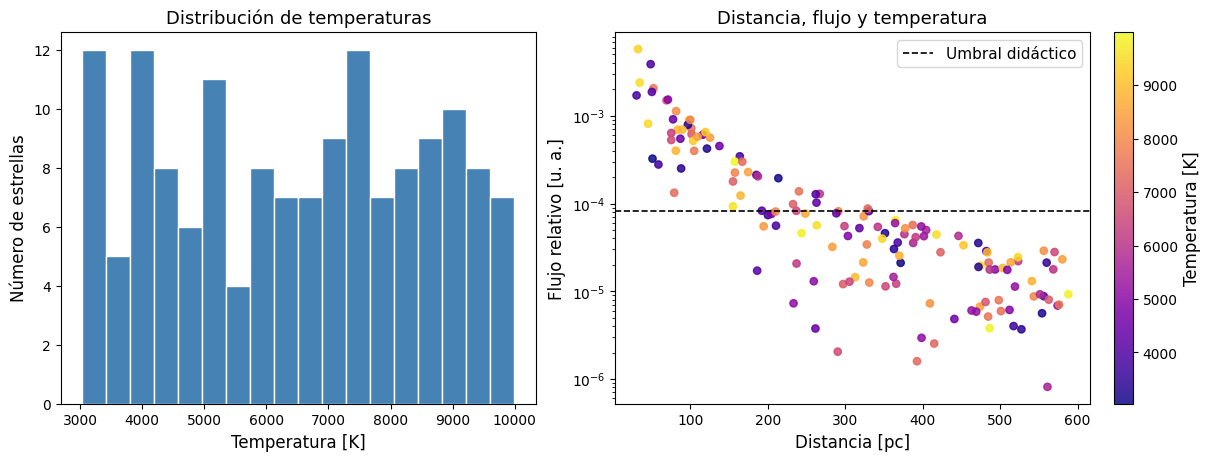

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(catalogo["T_K"], bins=18, edgecolor="white", color="steelblue")
ax1.set(xlabel="Temperatura [K]", ylabel="Número de estrellas", title="Distribución de temperaturas")

sc = ax2.scatter(catalogo["d_pc"], catalogo["flujo_rel"],c=catalogo["T_K"], cmap="plasma", s=28, alpha=0.85,) #ahora los colores lo dictan las temperaturas del catalogo

ax2.axhline(umbral, ls="--", color="black", lw=1.2, label="Umbral didáctico")
ax2.set(xlabel="Distancia [pc]", ylabel="Flujo relativo [u. a.]", yscale="log", title="Distancia, flujo y temperatura",) # u. a.  -> unidades arbitrarias
ax2.legend()
fig.colorbar(sc, ax=ax2, label="Temperatura [K]")
plt.show()

## 4. De un catálogo a una imagen: Moffat 2D

La PSF de una estrella puede aproximarse mediante un perfil de Moffat circular:


$I(x,y) = A\left[1 + \frac{(x-x_0)^2+(y-y_0)^2}{\alpha^2}\right]^{-\beta},$

con `A` como intensidad central, `(x₀, y₀)` como posición y `α`, `β` como parámetros de forma. Para `β > 1`, su flujo integrado hasta radio infinito es

$F_{\infty} = \frac{\pi A\alpha^2}{\beta-1}.$

In [ ]:
def moffat_2d(x, y, x0, y0, amplitud, alpha=2.6, beta=3.2):
    """Evalúa un perfil de Moffat circular en una grilla 2D.

    Parameters
    ----------
    x, y : numpy.ndarray
        Coordenadas en píxeles; deben admitir broadcasting.
    x0, y0 : float or numpy.ndarray
        Posiciones centrales, en píxeles.
    amplitud : float or numpy.ndarray
        Intensidad en el centro (unidades arbitrarias).
    alpha : float, optional
        Escala radial en píxeles (debe ser positiva).
    beta : float, optional
        Índice de forma del perfil (debe ser positivo).

    Returns
    -------
    numpy.ndarray
        Intensidad del perfil de Moffat en cada coordenada.
    """
    if alpha <= 0 or beta <= 0:
        raise ValueError("alpha y beta deben ser positivos")
    radio2 = (x - x0)**2 + (y - y0)**2
    return amplitud * (1 + radio2 / alpha**2)**(-beta)

### `meshgrid`, `mgrid` y broadcasting con una dimensión extra

- `np.meshgrid(x, y)` construye matrices de coordenadas a partir de vectores de ejes.
- `np.mgrid[:alto, :ancho]` construye una grilla densa de índices (`Y`, `X`).
- `X[None, :, :]` añade un eje para evaluar **varias estrellas al mismo tiempo**, sin un bucle por píxel.

Seleccionaremos las cinco estrellas de mayor flujo relativo y las ubicaremos en posiciones separadas de una imagen de `96 × 96` píxeles. La amplitud en la imagen será una transformación visual arbitraria del flujo del catálogo.

In [ ]:
# Cinco objetos del mismo catálogo, ahora con posiciones en píxeles.
fuentes = catalogo.nlargest(5, "flujo_rel").copy().reset_index(drop=True)
posiciones = np.array([[18, 20], [43, 31], [74, 18], [28, 73], [78, 75]])
fuentes["x_pix"] = posiciones[:, 0]
fuentes["y_pix"] = posiciones[:, 1]
fuentes["amplitud"] = 60 + 220 * fuentes["flujo_rel"] / fuentes["flujo_rel"].max()

In [ ]:
fuentes["x_pix"] = posiciones[:, 0]
fuentes["y_pix"] = posiciones[:, 1]
fuentes["amplitud"] = 60 + 220 * fuentes["flujo_rel"] / fuentes["flujo_rel"].max()

alto, ancho = 96, 96
Y, X = np.mgrid[:alto, :ancho]

alpha, beta = 2.0, 1.0

x0 = fuentes["x_pix"].to_numpy()[:, None, None]
y0 = fuentes["y_pix"].to_numpy()[:, None, None]
A = fuentes["amplitud"].to_numpy()[:, None, None]

cubo_estrellas = moffat_2d(X[None, :, :], Y[None, :, :], x0, y0, A, alpha, beta)
modelo = cubo_estrellas.sum(axis=0)

fondo = 10.0
sigma_ruido = 1.8
imagen = modelo + fondo + rng.normal(0, sigma_ruido, size=modelo.shape)

print("Forma de cada estrella apilada:", cubo_estrellas.shape)
print("Forma de la imagen final:", imagen.shape)
display(fuentes[["id", "x_pix", "y_pix", "amplitud"]])

assert imagen.shape == (alto, ancho)

Forma de cada estrella apilada: (5, 96, 96)
Forma de la imagen final: (96, 96)


,id,x_pix,y_pix,amplitud
0,EST-050,18,20,280.00000
1,EST-067,43,31,208.03397
2,EST-007,74,18,151.16933
3,EST-051,28,73,138.51662
4,EST-072,78,75,131.40326


### imagen 2D y escala de colores

Conviene visualizar por separado el modelo sin ruido y la imagen simulada. `origin="lower"` sitúa el origen en la esquina inferior izquierda (como `Numpy`). `vmin`/`vmax` permiten usar la misma escala en ambas imágenes.

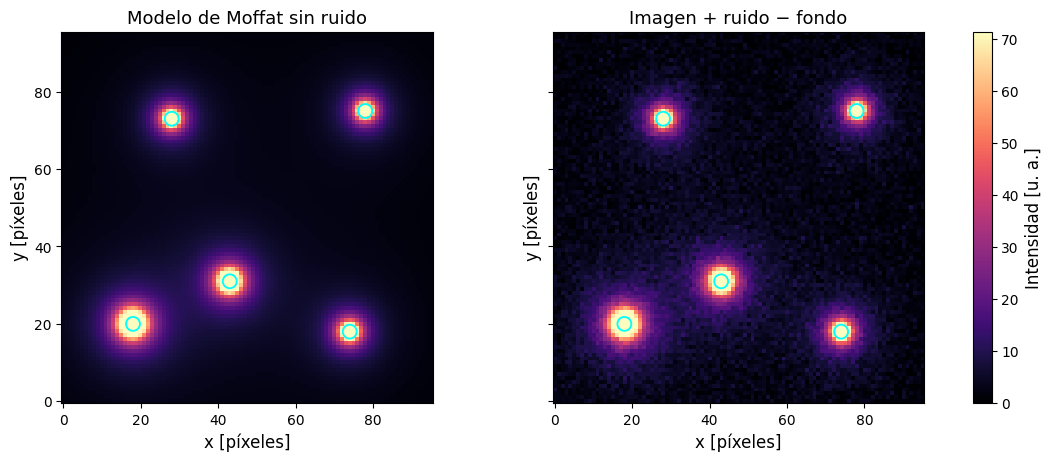

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)

vmin, vmax = 0, np.percentile(imagen - fondo, 99.)
im0 = ejes[0].imshow(modelo, origin="lower", cmap="magma", vmin=vmin, vmax=vmax)
im1 = ejes[1].imshow(imagen - fondo, origin="lower", cmap="magma", vmin=vmin, vmax=vmax)

ejes[0].set_title("Modelo de Moffat sin ruido")
ejes[1].set_title("Imagen + ruido − fondo")
for ax in ejes:
    ax.scatter(fuentes["x_pix"], fuentes["y_pix"], s=100, facecolors="none", edgecolors="cyan", lw=1.3)
    ax.set(xlabel="x [píxeles]", ylabel="y [píxeles]")
fig.colorbar(im1, ax=ejes, label="Intensidad [u. a.]", shrink=1.0)
plt.show()

### `contour` vs. `contourf`

`contour` dibuja **líneas de nivel** y puede etiquetarlas mediante `ax.clabel`. `contourf` **rellena regiones** entre niveles. Ambos trabajan con una matriz 2D, opcionalmente acompañada de las grillas `X` e `Y`. Usaremos la imagen sin fondo para que los niveles estén asociados a la señal estelar.

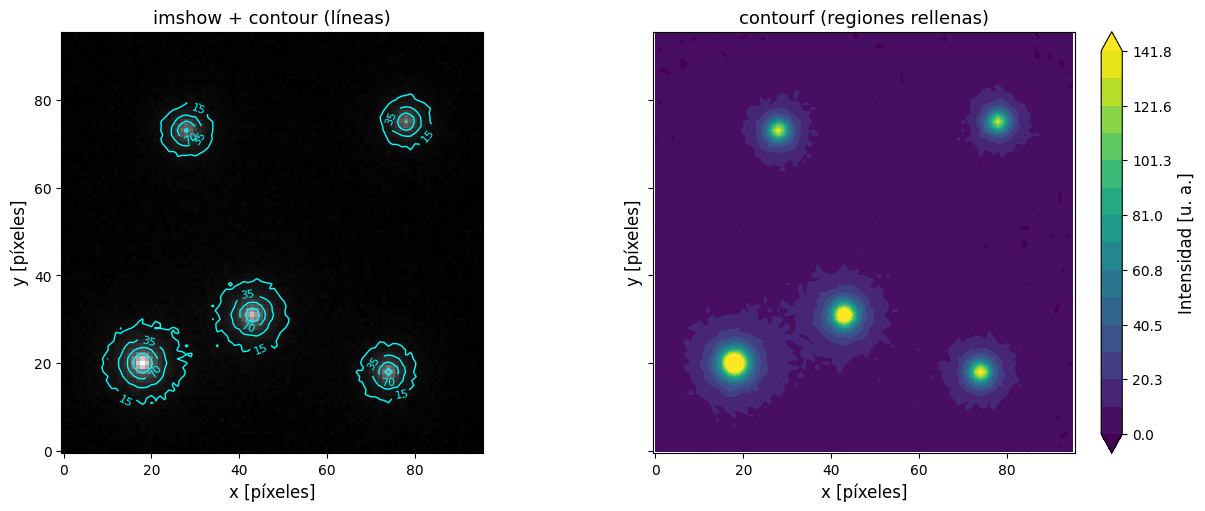

In [ ]:
senal = imagen - fondo
niveles_linea = [15, 35, 70, 130]
niveles_relleno = np.linspace(0, np.percentile(senal, 99.8), 15)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

im = ejes[0].imshow(senal, origin="lower", cmap="gray", vmin=0)
cs = ejes[0].contour(X, Y, senal, levels=niveles_linea, colors="cyan", linewidths=1.0)
ejes[0].clabel(cs, inline=True, fontsize=8, fmt="%.0f")
ejes[0].set_title("imshow + contour (líneas)")

cf = ejes[1].contourf(X, Y, senal, levels=niveles_relleno, cmap="viridis", extend="both")
ejes[1].set_title("contourf (regiones rellenas)")
fig.colorbar(cf, ax=ejes[1], label="Intensidad [u. a.]")

for ax in ejes:
    ax.set(xlabel="x [píxeles]", ylabel="y [píxeles]", aspect="equal")
plt.show()

### `meshgrid` o `mgrid`

La grilla de arriba también puede construirse con dos vectores 1D. Comprobemos que `meshgrid` y `mgrid` describen las mismas coordenadas.

In [ ]:
x = np.arange(ancho)
y = np.arange(alto)
X2, Y2 = np.meshgrid(x, y)

print("X2:", X2.shape, "| Y2:", Y2.shape)
print("Coincide con mgrid:", np.array_equal(X, X2) and np.array_equal(Y, Y2))
assert np.array_equal(X, X2)
assert np.array_equal(Y, Y2)

X2: (96, 96) | Y2: (96, 96)
Coincide con mgrid: True


## 5. Máscaras circulares con `ogrid` y operaciones sobre píxeles

`np.ogrid` crea arreglos de coordenadas **abiertos**: `Y` tiene forma `(alto, 1)` y `X` forma `(1, ancho)`. Se combinan por broadcasting para crear máscaras sin almacenar dos grillas completas de coordenadas.

Una máscara booleana permite seleccionar los píxeles dentro de una apertura circular. Definimos el centro como **`(x, y)`**, no como `(fila, columna)`.

Máscara: (96, 96) | dtype: bool
Píxeles seleccionados: 197
Área ideal del círculo: 201.06192982974676


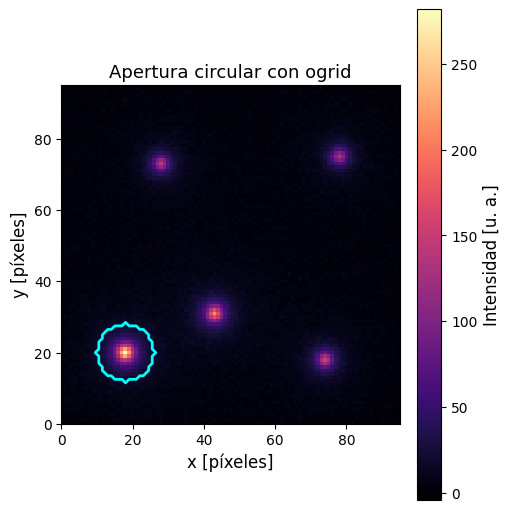

In [ ]:
def mascara_circular(forma, centro, radio):
    """Crea una máscara circular de una imagen.

    Parameters
    ----------
    forma : tuple of int
        Dimensiones de la imagen como (alto, ancho).
    centro : tuple of float
        Centro de la apertura como (x, y), en píxeles.
    radio : float
        Radio de la apertura, en píxeles.

    Returns
    -------
    numpy.ndarray of bool
        Matriz booleana: True dentro de la apertura.
    """
    if radio <= 0:
        raise ValueError("radio debe ser positivo")
    alto_local, ancho_local = forma
    yc, xc = np.ogrid[:alto_local, :ancho_local]
    x0_local, y0_local = centro
    return (xc - x0_local)**2 + (yc - y0_local)**2 <= radio**2

fuente_principal = fuentes.iloc[0]
centro = (float(fuente_principal["x_pix"]), float(fuente_principal["y_pix"]))
radio_ap = 8.0
mascara = mascara_circular(imagen.shape, centro, radio_ap)

print("Máscara:", mascara.shape, "| dtype:", mascara.dtype)
print("Píxeles seleccionados:", mascara.sum())
print("Área ideal del círculo:", np.pi * radio_ap**2)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(senal, origin="lower", cmap="magma")
ax.contour(mascara.astype(int), levels=[0.5], colors="cyan", linewidths=2)
ax.set(xlim=(0, ancho-1), ylim=(0, alto-1), xlabel="x [píxeles]", ylabel="y [píxeles]", title="Apertura circular con ogrid")
fig.colorbar(im, ax=ax, label="Intensidad [u. a.]")
plt.show()

### Medición del flujo en una apertura

Si conocemos el fondo uniforme de la simulación, podemos estimar el flujo dentro de la apertura sumando `imagen[mascara] - fondo`. La apertura no captura todo el perfil y el ruido introduce una pequeña diferencia adicional.

Para un Moffat circular ideal con `β > 1`, la fracción de flujo encerrado en radio `R` es


$\frac{F(<R)}{F_\infty} = 1 - \left(1 + \frac{R^2}{\alpha^2}\right)^{1-\beta}.$

In [ ]:
flujo_apertura = np.sum(imagen[mascara] - fondo)
flujo_total_ideal = np.pi * fuente_principal["amplitud"] * alpha**2 / (beta - 1)
fraccion_ideal = 1 - (1 + (radio_ap / alpha)**2)**(1 - beta)
flujo_apertura_ideal = flujo_total_ideal * fraccion_ideal

print(f"Flujo medido dentro de R={radio_ap:.1f} px: {flujo_apertura:.2f} u. a.")
print(f"Flujo ideal en la misma apertura: {flujo_apertura_ideal:.2f} u. a.")
print(f"Flujo ideal hasta infinito: {flujo_total_ideal:.2f} u. a.")
print(f"Fracción ideal encerrada: {fraccion_ideal:.1%}")

Flujo medido dentro de R=8.0 px: 2636.98 u. a.
Flujo ideal en la misma apertura: 2687.49 u. a.
Flujo ideal hasta infinito: 2702.91 u. a.
Fracción ideal encerrada: 99.4%


In [ ]:
registros = []
for fuente in fuentes.itertuples(index=False):
    mk = mascara_circular(imagen.shape, (fuente.x_pix, fuente.y_pix), radio_ap)
    flujo_medido = np.sum((imagen - fondo)[mk])
    # Flujo esperado en exactamente los mismos píxeles: comparación justa.
    flujo_modelo_apertura = np.sum(modelo[mk])
    registros.append({"id": fuente.id,"flujo_apertura": flujo_medido, "flujo_modelo_apertura": flujo_modelo_apertura,"n_pixeles": int(mk.sum()),})

fotometria = pd.DataFrame(registros)
fotometria["residuo"] = fotometria["flujo_apertura"] - fotometria["flujo_modelo_apertura"]
fotometria["error_rel_pct"] = 100 * fotometria["residuo"] / fotometria["flujo_modelo_apertura"]

fotometria

,id,flujo_apertura,flujo_modelo_apertura,n_pixeles,residuo,error_rel_pct
0,EST-050,10162.07560,10219.72465,197,-57.64905,-0.56410
1,EST-067,7848.42852,7859.09561,197,-10.66708,-0.13573
2,EST-007,5646.70481,5617.66546,197,29.03934,0.51693
3,EST-051,5088.64373,5122.66028,197,-34.01655,-0.66404
4,EST-072,4762.95860,4812.53822,197,-49.57962,-1.03022


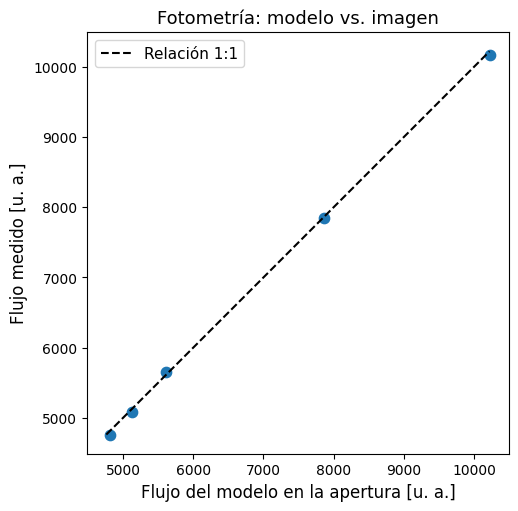

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(fotometria["flujo_modelo_apertura"], fotometria["flujo_apertura"], s=55)
limites = [min(fotometria[["flujo_modelo_apertura", "flujo_apertura"]].min()),
           max(fotometria[["flujo_modelo_apertura", "flujo_apertura"]].max())]
ax.plot(limites, limites, ls="--", color="black", label="Relación 1:1")
ax.set(xlabel="Flujo del modelo en la apertura [u. a.]",
       ylabel="Flujo medido [u. a.]", title="Fotometría: modelo vs. imagen")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()